# Resource prediction

How much time do reruns cost us, which processes do they hit, and can STARsolo's memory request be
predicted from the input so that big samples stop failing on their first attempt? §11 asks the
same of SRA2FASTQ.

**Data** (read-only):

| source | what | batches |
|---|---|---|
| `/nfs/cellgeni/reprocessing-runs/batch*/*/runlogs<N>.tsv.gz` | Nextflow trace of every task, all processes | 1-23 |
| `…/<run>/execution_trace_*.txt.gz` for runs without a runlogs file | same, older export | 4 (`fervent_raman`), 5 (`awesome_neumann`) |
| `…/mapping_qc_stats.tsv` | `Rd_all` = STAR's *Number of input reads*, `WL`, `Paired` per sample | 9-23 |
| `reports/execution_trace_2026-10-07_09-00-27.txt` | live trace | 24 |
| `results/batch24/starsolo/<GSE>/<GSM>/Log.final.out` | input reads **and** average read length | 24 |
| batch-24 `nf-work` STARsolo dirs | the staged FASTQs themselves (only while batch 24 is in flight) | 24 |

The `legacy/august-2026-baseline` runlogs are left out: they cannot be attributed to a run and may
overlap batch 1.

**Caveats**
- Every task retries once whatever its exit code (`nextflow.config` `errorStrategy`), so an
  `attempt=2` row is not by itself evidence of anything. What counts is whether a later attempt
  succeeded.
- Exit 130 is in practice LSF `TERM_MEMLIMIT`, so the task's true peak is only known to be above the
  request: a *censored* point. Exit 139 is a STAR segfault, not memory, and is not used for the
  memory model.

**Run** from the repo root. Section 7 reads the head of several hundred FASTQs on Lustre, so it goes
to LSF, not the head node:
```bash
.claude/skills/reprocess-debug/bin/farm_run.sh --name nb-starsolo --mem 16G --cpus 8 --time 2:00 -- \
  'uvx --from nbconvert --with pandas --with matplotlib --with statsmodels --with ipykernel \
     jupyter-nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 \
     notebooks/resource_prediction.ipynb'
```

In [1]:
import json, os, re, zlib
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
ARCHIVE = Path('/nfs/cellgeni/reprocessing-runs')
LIVE_BATCH = 'batch24'
LIVE_TRACE = REPO / 'reports/execution_trace_2026-10-07_09-00-27.txt'
LIVE_RESULTS = REPO / 'results/batch24'

# Batches used to *fit* the model; later ones are held out for the policy simulation.
TRAIN_BATCHES = {f'batch{n}' for n in range(9, 22)} | {'batch12-13'}

pd.set_option('display.width', 200, 'display.max_columns', 30, 'display.max_rows', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

## 1. Load and parse every trace

In [2]:
_UNIT = {'B': 1e-9, 'KB': 1e-6, 'MB': 1e-3, 'GB': 1.0, 'TB': 1e3}
_DUR = re.compile(r'([\d.]+)\s*(ms|d|h|m|s)')
_DUR_H = {'ms': 1 / 3.6e6, 's': 1 / 3600, 'm': 1 / 60, 'h': 1, 'd': 24}

def to_gb(s):
    if not isinstance(s, str) or s.strip() in ('', '-'):
        return np.nan
    v, u = s.split()
    return float(v) * _UNIT[u]

def to_hours(s):
    if not isinstance(s, str) or s.strip() in ('', '-'):
        return np.nan
    return sum(float(v) * _DUR_H[u] for v, u in _DUR.findall(s))

def batch_no(b):
    return int(re.search(r'\d+', b).group())

COLS = ['process', 'tag', 'name', 'status', 'exit', 'attempt', 'realtime', 'duration', 'queue',
        'cpus', 'memory', 'peak_rss', 'workdir', 'submit', 'start', 'complete']

def read_trace(path, batch, run):
    d = pd.read_csv(path, sep='\t', dtype=str)
    for c in COLS:
        if c not in d:
            d[c] = np.nan
    return d[COLS].assign(batch=batch, run=run)

frames = []
for run_dir in sorted(p for p in ARCHIVE.glob('batch*/*') if p.is_dir()):
    runlogs = sorted(run_dir.glob('runlogs*.tsv.gz'))
    traces = sorted(run_dir.glob('execution_trace_*.txt.gz'))
    src = runlogs or traces            # runlogs is the fuller export; fall back to the raw trace
    for f in src:
        frames.append(read_trace(f, run_dir.parent.name, run_dir.name))
frames.append(read_trace(LIVE_TRACE, LIVE_BATCH, 'live'))
raw = pd.concat(frames, ignore_index=True)
print(raw.groupby('batch').run.unique().to_string())

df = raw[raw.status.isin(['COMPLETED', 'FAILED'])].copy()   # CACHED rows were paid for by an earlier run
df['attempt'] = pd.to_numeric(df.attempt, errors='coerce').astype('Int64')
df['cpus'] = pd.to_numeric(df.cpus, errors='coerce')
df['req_gb'] = df.memory.map(to_gb)
df['peak_gb'] = df.peak_rss.map(to_gb)
# realtime is '-' on tasks LSF killed; fall back to start→complete, then to duration (includes queueing)
span = (pd.to_datetime(df.complete, errors='coerce') - pd.to_datetime(df.start, errors='coerce')).dt.total_seconds() / 3600
df['hours'] = df.realtime.map(to_hours).fillna(span).fillna(df.duration.map(to_hours))
df['core_h'] = df.cpus * df.hours
df['step'] = (df.process.str.split(':').str[-1]
                .str.replace('REPROCESS10X_', '', regex=False)
                .str.replace('STARSOLO10X', 'STARSOLO', regex=False))
df.loc[df.process.str.contains('_MOUSE', na=False), 'step'] += ' (mouse)'
df['exit_class'] = np.select(
    [df.status == 'COMPLETED', df.exit == '130', df.exit == '139', df.exit.isin(['140', '146']), df.exit == '104'],
    ['ok', '130 memlimit', '139 segfault', '140/146 LSF kill', '104 STAR fatal'],
    default='other (' + df.exit.fillna('-') + ')')
df['bno'] = df.batch.map(batch_no)
print(f'{len(df):,} executed task attempts in {df.batch.nunique()} batches, '
      f'{df.core_h.sum():,.0f} core-h in total')
df.groupby('step').agg(attempts=('name', 'size'), core_h=('core_h', 'sum')).sort_values('core_h', ascending=False).round(0)

batch
batch1                        [peaceful_feynman]
batch10                        [trusting_carson]
batch11                       [irreverent_elion]
batch12-13                      [boring_hawking]
batch14                          [maniac_keller]
batch15                   [infallible_dalembert]
batch16                            [sad_brenner]
batch17                          [cranky_cuvier]
batch18                     [compassionate_shaw]
batch19                       [focused_goldberg]
batch2                     [distraught_mercator]
batch20                           [sleepy_curie]
batch21                           [sick_galileo]
batch22                          [gloomy_church]
batch23                        [exotic_dijkstra]
batch24                                   [live]
batch3                              [big_keller]
batch4          [fervent_raman, nauseous_spence]
batch5        [awesome_neumann, tender_brattain]
batch6                      [spontaneous_ampere]
batch7        

242,756 executed task attempts in 23 batches, 473,635 core-h in total


,attempts,core_h
step,,
STARSOLO,23980,376980.0
SRA2FASTQ,29810,83081.0
WGET10X,96979,8600.0
RENAME10XRUN,63534,4929.0
BAM2FASTQ,5,26.0
FETCH10XMETA,2569,10.0
RENAME10XSAMPLE,23567,5.0
MAPPINGQC,2312,4.0


## 2. Rerun evidence: where the retries happen and what they cost

A *task* is one `(batch, process, name)`. Its outcome is

- **first try**: no failed attempt;
- **recovered**: failed at least once, then succeeded. The failed attempts are pure waste, and they
  also delay the sample by their runtime plus a second queue wait;
- **permanent**: never succeeded. Every attempt is spent for nothing, but retrying a doomed task is
  the deliberate price of not losing transient failures.

The same GSM aligned under two GSEs gives two tasks with one `name` in batches 8-21. They are
counted together, which slightly inflates "recovered" there but not the core-hours.

In [3]:
g = df.groupby(['batch', 'process', 'name'], sort=False)
tasks = g.agg(step=('step', 'first'), bno=('bno', 'first'),
              n_ok=('status', lambda s: (s == 'COMPLETED').sum()),
              n_fail=('status', lambda s: (s == 'FAILED').sum()),
              core_h=('core_h', 'sum')).reset_index()
tasks['outcome'] = np.select([tasks.n_fail == 0, tasks.n_ok > 0], ['first try', 'recovered'], 'permanent')
df = df.merge(tasks[['batch', 'process', 'name', 'outcome']], on=['batch', 'process', 'name'])
fails = df[df.status == 'FAILED']

by_step = pd.DataFrame({
    'tasks': tasks.groupby('step').size(),
    'recovered': tasks[tasks.outcome == 'recovered'].groupby('step').size(),
    'permanent': tasks[tasks.outcome == 'permanent'].groupby('step').size(),
    'total core-h': df.groupby('step').core_h.sum(),
    'wasted core-h (recovered)': fails[fails.outcome == 'recovered'].groupby('step').core_h.sum(),
    'wasted core-h (permanent)': fails[fails.outcome == 'permanent'].groupby('step').core_h.sum(),
}).fillna(0)
by_step['% of step wasted'] = 100 * (by_step['wasted core-h (recovered)'] + by_step['wasted core-h (permanent)']) / by_step['total core-h']
by_step = by_step.sort_values('wasted core-h (recovered)', ascending=False)
tot = by_step[['wasted core-h (recovered)', 'wasted core-h (permanent)']].sum()
print(f"all batches: {tot.sum():,.0f} core-h on failed attempts "
      f"({tot.iloc[0]:,.0f} before an eventual success, {tot.iloc[1]:,.0f} on tasks that never succeeded); "
      f"{100 * tot.sum() / df.core_h.sum():.1f}% of everything run")
by_step.round(1)

all batches: 21,371 core-h on failed attempts (11,144 before an eventual success, 10,228 on tasks that never succeeded); 4.5% of everything run


,tasks,recovered,permanent,total core-h,wasted core-h (recovered),wasted core-h (permanent),% of step wasted
step,,,,,,,
STARSOLO,20386,149.0,200.0,376980.2,9625.5,8378.3,4.8
SRA2FASTQ,25877,14.0,141.0,83081.0,1202.1,1795.8,3.6
WGET10X,81101,327.0,20.0,8600.4,302.2,26.6,3.8
RENAME10XRUN,54540,24.0,977.0,4928.6,13.8,26.8,0.8
FETCH10XMETA,2355,10.0,35.0,9.6,0.0,0.1,1.5
RENAME10XSAMPLE,20400,1.0,6.0,5.4,0.0,0.0,0.2
MAPPINGQC,2311,0.0,0.0,4.4,0.0,0.0,0.0
BAM2FASTQ,5,0.0,0.0,25.6,0.0,0.0,0.0


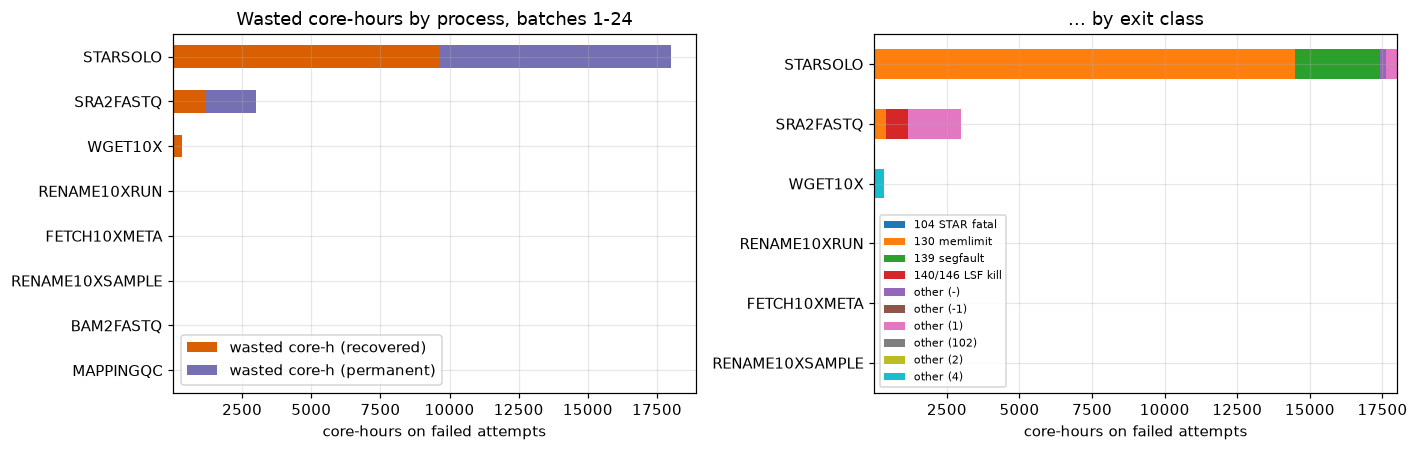

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
w = by_step[['wasted core-h (recovered)', 'wasted core-h (permanent)']].sort_values('wasted core-h (recovered)')
w.plot.barh(stacked=True, ax=ax[0], color=['#d95f02', '#7570b3'])
ax[0].set(xlabel='core-hours on failed attempts', ylabel='', title='Wasted core-hours by process, batches 1-24')

ex = fails.pivot_table(index='step', columns='exit_class', values='core_h', aggfunc='sum', fill_value=0)
ex = ex.loc[ex.sum(axis=1).sort_values().index]
ex.plot.barh(stacked=True, ax=ax[1], colormap='tab10')
ax[1].set(xlabel='core-hours on failed attempts', ylabel='', title='… by exit class')
ax[1].legend(fontsize=7)
plt.tight_layout()

In [5]:
# By exit class across all processes: how often a retry fixes it
ec = fails.groupby(['step', 'exit_class']).agg(
    attempts=('name', 'size'),
    core_h=('core_h', 'sum'),
    recovered=('outcome', lambda s: (s == 'recovered').sum())).reset_index()
ec['recovered %'] = 100 * ec.recovered / ec.attempts
ec.sort_values('core_h', ascending=False).head(20).round(1)

,step,exit_class,attempts,core_h,recovered,recovered %
11,STARSOLO,130 memlimit,164,14454.1,119,72.6
12,STARSOLO,139 segfault,308,2938.2,1,0.3
9,SRA2FASTQ,other (1),885,1838.7,12,1.4
8,SRA2FASTQ,140/146 LSF kill,1,768.0,1,100.0
7,SRA2FASTQ,130 memlimit,1,391.2,1,100.0
14,STARSOLO,other (1),206,367.2,34,16.5
19,WGET10X,other (4),526,313.1,504,95.8
13,STARSOLO,other (-),1,221.1,0,0.0
4,RENAME10XRUN,other (2),2527,27.1,17,0.7
10,STARSOLO,104 STAR fatal,4,21.5,3,75.0


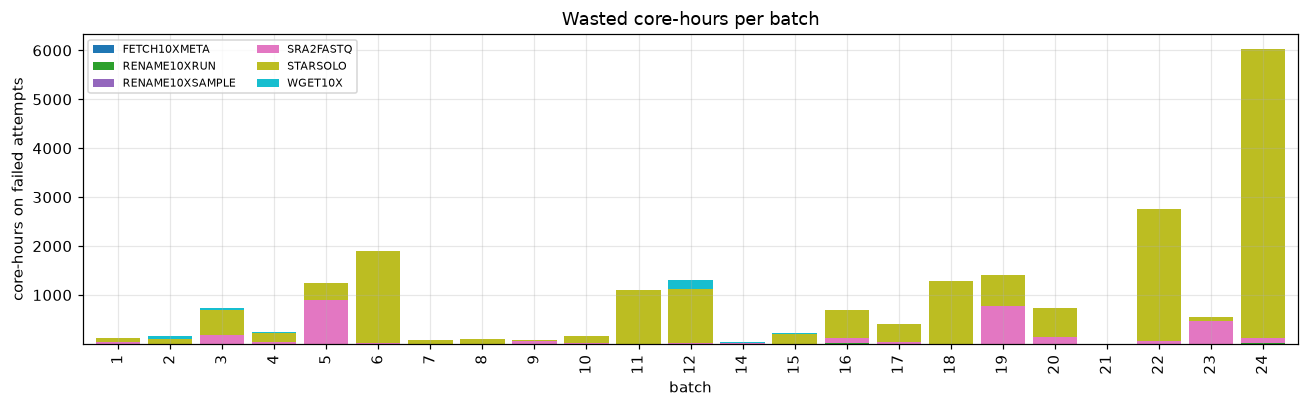

In [6]:
# Per batch, wasted core-h by process (top 6 processes, rest pooled)
top = by_step.index[:6]
fb = fails.assign(step=fails.step.where(fails.step.isin(top), 'other'))
pb = fb.pivot_table(index='bno', columns='step', values='core_h', aggfunc='sum', fill_value=0)
ax = pb.plot.bar(stacked=True, figsize=(12, 3.8), colormap='tab10', width=.85)
ax.set(xlabel='batch', ylabel='core-hours on failed attempts', title='Wasted core-hours per batch')
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()

In [7]:
# Delay: wall-clock a sample loses before its successful attempt even starts (runtime of failed attempts;
# the extra queue wait comes on top and is not in the trace for every batch)
delay = (fails[fails.outcome == 'recovered']
         .groupby(['batch', 'step', 'name']).hours.sum()
         .groupby('step').describe(percentiles=[.5, .9])[['count', 'mean', '50%', '90%', 'max']])
delay.columns = ['recovered tasks', 'mean h lost', 'median h', 'p90 h', 'max h']
delay.sort_values('recovered tasks', ascending=False).round(2)

,recovered tasks,mean h lost,median h,p90 h,max h
step,,,,,
WGET10X,327.0,0.92,0.57,2.21,11.20
STARSOLO,149.0,4.04,3.81,6.78,17.17
RENAME10XRUN,24.0,0.58,0.05,0.23,12.03
SRA2FASTQ,14.0,5.37,0.24,17.31,48.00
FETCH10XMETA,10.0,0.00,0.00,0.00,0.01
RENAME10XSAMPLE,1.0,0.00,0.00,0.00,0.00


## 3. Over-provisioning: memory reserved but never used

LSF reserves the whole request for the job's lifetime (`perJobMemLimit`). Unused reservation never
shows up as a failure, but it limits how many jobs fit on a host and therefore lengthens the queue.
Completed attempts only.

In [8]:
ok = df[(df.status == 'COMPLETED') & df.peak_gb.notna() & df.req_gb.notna()]
op = ok.assign(res=ok.req_gb * ok.hours, used=ok.peak_gb * ok.hours).groupby('step').agg(
    tasks=('name', 'size'), req_gb_median=('req_gb', 'median'), peak_gb_median=('peak_gb', 'median'),
    peak_gb_p99=('peak_gb', lambda s: s.quantile(.99)),
    reserved_TBh=('res', lambda s: s.sum() / 1e3), used_TBh=('used', lambda s: s.sum() / 1e3))
op['used / reserved %'] = 100 * op.used_TBh / op.reserved_TBh
op.sort_values('reserved_TBh', ascending=False).round(1)

,tasks,req_gb_median,peak_gb_median,peak_gb_p99,reserved_TBh,used_TBh,used / reserved %
step,,,,,,,
STARSOLO,23293,128.0,51.6,130.4,2969.8,1562.7,52.6
SRA2FASTQ,28922,128.0,4.1,5.6,641.2,25.9,4.0
WGET10X,96176,4.0,0.0,0.0,34.0,0.1,0.2
RENAME10XRUN,60994,4.0,2.5,2.6,19.6,12.4,63.3
FETCH10XMETA,2374,4.0,0.0,0.0,0.0,0.0,0.6
RENAME10XSAMPLE,23550,4.0,0.0,0.0,0.0,0.0,0.4
MAPPINGQC,2312,2.0,0.0,0.0,0.0,0.0,0.4
BAM2FASTQ,5,4.0,0.0,0.0,0.0,0.0,1.0


## 4. STARsolo modelling table

One row per STARsolo attempt, with the sample's input reads attached:

- batches 9-23: `Rd_all` from `mapping_qc_stats.tsv`, joined on `tag == Sample`;
- batch 24: `Log.final.out`, which also gives the average input read length.

Completed attempts give an observed `peak_gb`. Exit-130 attempts give a lower bound `> req_gb`.

In [9]:
qc = pd.concat([pd.read_csv(f, sep='\t', dtype={'Sample': str}).assign(batch=f.parts[-3])
                for f in ARCHIVE.glob('batch*/*/mapping_qc_stats.tsv')], ignore_index=True)
qc = qc.drop_duplicates(['batch', 'Sample'])[['batch', 'Sample', 'Rd_all', 'WL', 'Paired']]

def parse_log_final(p):
    kv = {}
    for line in p.read_text().splitlines():
        if '|' in line:
            k, v = line.split('|', 1)
            kv[k.strip()] = v.strip()
    return {'batch': LIVE_BATCH, 'Sample': p.parent.name,
            'Rd_all': int(kv['Number of input reads']),
            'read_len': float(kv['Average input read length'])}

lf = pd.DataFrame([parse_log_final(p) for p in LIVE_RESULTS.glob('starsolo/*/*/Log.final.out')])
lf = lf.drop_duplicates(['batch', 'Sample'])
reads = pd.concat([qc, lf], ignore_index=True)
print(f'{len(qc):,} QC rows (batches 9-23), {len(lf):,} batch-24 Log.final.out')

star = df[df.step == 'STARSOLO'].merge(reads, left_on=['batch', 'tag'], right_on=['batch', 'Sample'], how='left')
star['R'] = star.Rd_all / 1e9           # input reads, 10^9
star['censored'] = star.exit_class == '130 memlimit'
star['split'] = np.where(star.batch.isin(TRAIN_BATCHES), 'train',
                       np.where(star.bno >= 22, 'holdout', 'no reads'))
obs = star[(star.status == 'COMPLETED') & star.R.notna() & star.peak_gb.notna()].copy()
cens = star[star.censored & star.R.notna()].copy()
print(f'{len(obs):,} completed STARsolo attempts with reads ({(obs.split == "train").sum():,} train, '
      f'{(obs.split == "holdout").sum():,} hold-out); {len(cens)} memlimit kills with reads; '
      f'{star[star.censored & star.R.isna()].tag.nunique()} killed samples whose reads are unknown')

13,262 QC rows (batches 9-23), 392 batch-24 Log.final.out
15,779 completed STARsolo attempts with reads (11,998 train, 3,781 hold-out); 100 memlimit kills with reads; 52 killed samples whose reads are unknown


## 5. What drives STARsolo's peak memory

,count,50%,90%,99%,max
R_bin,,,,,
"(0.0, 0.1]",2858.0,36.4,43.6,47.3,48.8
"(0.1, 0.25]",4412.0,47.4,56.2,62.2,66.1
"(0.25, 0.5]",5776.0,57.4,70.6,83.9,93.7
"(0.5, 0.75]",1837.0,67.1,90.4,107.1,117.8
"(0.75, 1.0]",501.0,83.4,117.9,132.2,136.6
"(1.0, 1.25]",151.0,91.5,131.0,145.0,152.7
"(1.25, 1.5]",82.0,113.6,165.2,185.0,188.0
"(1.5, 2.0]",106.0,147.0,186.9,212.2,212.6
"(2.0, 10.0]",56.0,184.9,281.0,352.8,355.4


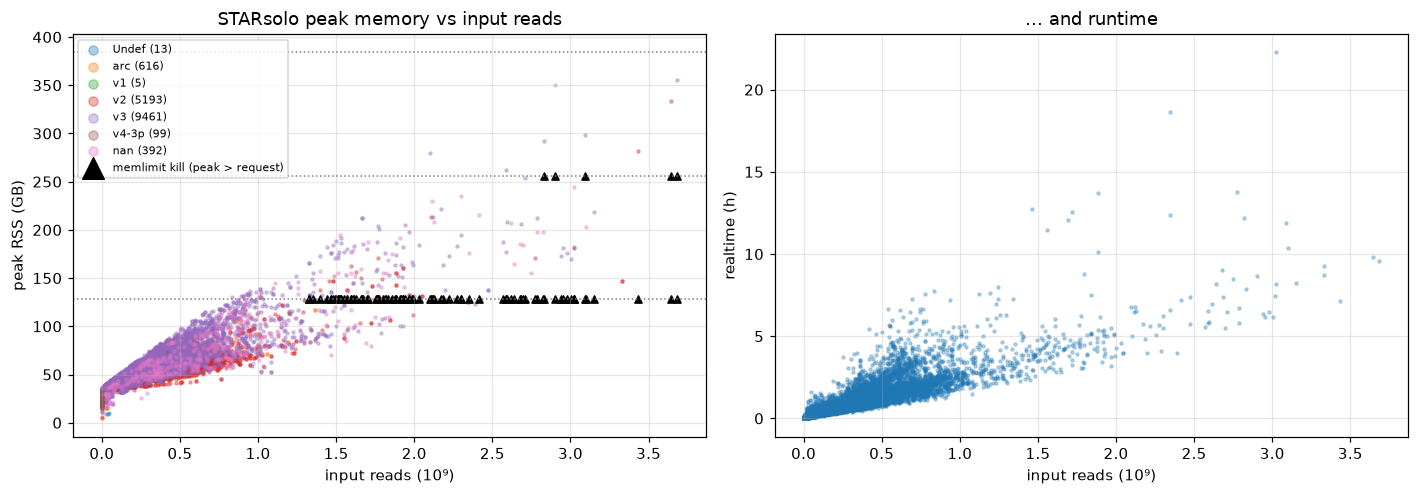

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for wl, d in obs.groupby('WL', dropna=False):
    ax[0].scatter(d.R, d.peak_gb, s=4, alpha=.35, label=f'{wl} ({len(d)})')
ax[0].scatter(cens.R, cens.req_gb, marker='^', s=22, c='k', label='memlimit kill (peak > request)')
for y in (128, 256, 384):
    ax[0].axhline(y, ls=':', c='grey', lw=1)
ax[0].set(xlabel='input reads (10⁹)', ylabel='peak RSS (GB)', title='STARsolo peak memory vs input reads')
ax[0].legend(fontsize=7, markerscale=3)

ax[1].scatter(obs.R, obs.hours, s=4, alpha=.3)
ax[1].set(xlabel='input reads (10⁹)', ylabel='realtime (h)', title='… and runtime')
plt.tight_layout()

bins = [0, .1, .25, .5, .75, 1, 1.25, 1.5, 2, 10]
obs['R_bin'] = pd.cut(obs.R, bins)
obs.groupby('R_bin', observed=True).peak_gb.describe(percentiles=[.5, .9, .99])[['count', '50%', '90%', '99%', 'max']].round(1)

## 6. Regression

The scatter shows a fan: both the level and the spread grow with reads. That suits **quantile
regression**, which fits each quantile with its own slope, so we fit straight lines at several
quantiles rather than one OLS line plus a constant margin. The model is fitted on batches 9-21 and
checked on 22-24.

In [11]:
train = obs[obs.split == 'train']
hold = obs[obs.split == 'holdout']

ols = smf.ols('peak_gb ~ R', train).fit()
print(f'OLS: peak = {ols.params.Intercept:.1f} + {ols.params.R:.1f}·R   (R² {ols.rsquared:.3f}, resid sd {np.sqrt(ols.scale):.1f} GB)')

QS = [.5, .9, .95, .99, .995]
rows, qfits = [], {}
for q in QS:
    for form in ('peak_gb ~ R', 'peak_gb ~ R + I(R**2)'):
        f = smf.quantreg(form, train).fit(q=q, max_iter=5000)
        qfits[(q, form)] = f
        pred = f.predict(hold)
        rows.append({'q': q, 'model': form.split('~')[1].strip(),
                     **{k: round(v, 2) for k, v in f.params.items()},
                     'hold-out coverage %': round(100 * (hold.peak_gb <= pred).mean(), 2),
                     'hold-out coverage, R>1 %': round(100 * (hold.peak_gb[hold.R > 1] <= pred[hold.R > 1]).mean(), 1)})
pd.DataFrame(rows)

OLS: peak = 36.2 + 60.4·R   (R² 0.739, resid sd 9.6 GB)


,q,model,Intercept,R,hold-out coverage %,"hold-out coverage, R>1 %",I(R ** 2)
0,0.500,R,35.12,61.60,55.14,51.1,NaN
1,0.500,R + I(R**2),34.16,69.86,55.28,26.6,-10.77
2,0.900,R,38.14,90.91,93.12,91.4,NaN
3,0.900,R + I(R**2),37.73,94.23,93.02,86.3,-3.60
4,0.950,R,37.93,99.53,96.40,97.1,NaN
5,0.950,R + I(R**2),37.40,104.96,96.46,94.2,-6.42
6,0.990,R,37.68,111.16,99.18,100.0,NaN
7,0.990,R + I(R**2),37.16,115.26,99.10,99.3,-5.91
8,0.995,R,37.28,115.67,99.44,100.0,NaN
9,0.995,R + I(R**2),37.35,115.33,99.42,100.0,0.15


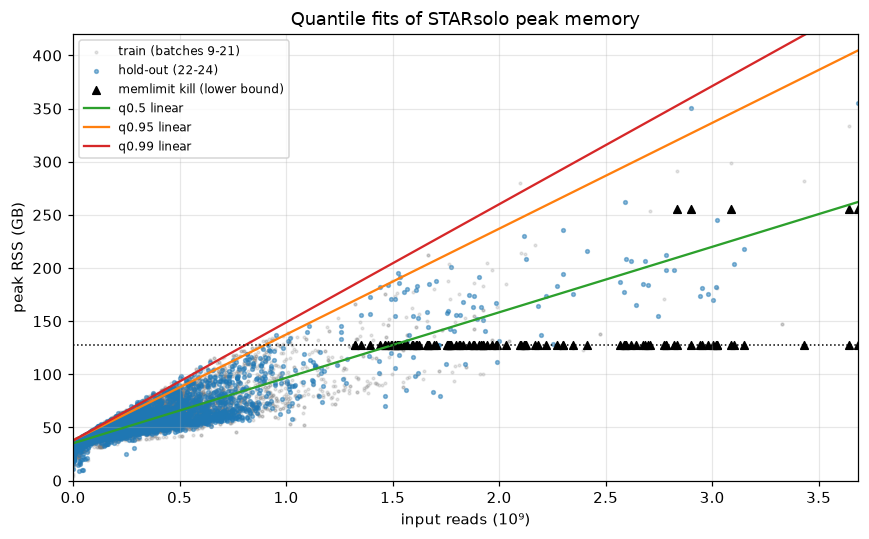

In [12]:
xs = pd.DataFrame({'R': np.linspace(0, max(3, obs.R.max()), 200)})
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train.R, train.peak_gb, s=3, alpha=.2, c='grey', label='train (batches 9-21)')
ax.scatter(hold.R, hold.peak_gb, s=6, alpha=.5, c='tab:blue', label='hold-out (22-24)')
ax.scatter(cens.R, cens.req_gb, marker='^', s=25, c='k', label='memlimit kill (lower bound)')
for q, c in zip([.5, .95, .99], ['tab:green', 'tab:orange', 'tab:red']):
    ax.plot(xs.R, qfits[(q, 'peak_gb ~ R')].predict(xs), c=c, label=f'q{q} linear')
ax.axhline(128, ls=':', c='k', lw=1)
ax.set(xlabel='input reads (10⁹)', ylabel='peak RSS (GB)', xlim=(0, xs.R.max()), ylim=(0, 420),
       title='Quantile fits of STARsolo peak memory')
ax.legend(fontsize=8)
plt.tight_layout()

In [13]:
# Do the memlimit kills fit the picture? A kill at request X says peak > X; the q99 line should
# sit above X for most of them, or the model would have been killed too.
q99 = qfits[(.99, 'peak_gb ~ R')]
cens['q99_pred'] = q99.predict(cens)
print(f'{len(cens)} memlimit kills with known reads: q99 prediction above the request that was killed '
      f'for {(cens.q99_pred > cens.req_gb).sum()} ({100 * (cens.q99_pred > cens.req_gb).mean():.0f}%)')
cens[['batch', 'tag', 'attempt', 'Rd_all', 'req_gb', 'q99_pred']].sort_values('Rd_all').round(1).tail(15)

100 memlimit kills with known reads: q99 prediction above the request that was killed for 100 (100%)


,batch,tag,attempt,Rd_all,req_gb,q99_pred
13325,batch22,GSM5223967,1,2.953023e+09,128.0,365.9
13293,batch22,GSM5223973,1,2.979374e+09,128.0,368.9
13282,batch22,GSM5223971,1,3.004604e+09,128.0,371.7
13292,batch22,GSM5223972,1,3.019718e+09,128.0,373.3
3097,batch12-13,GSM6939186,1,3.021887e+09,128.0,373.6
23640,batch24,SRS15070888,1,3.025085e+09,128.0,373.9
9203,batch18,GSM7716952,1,3.090478e+09,128.0,381.2
9431,batch18,GSM7716952,2,3.090478e+09,256.0,381.2
23635,batch24,GSM8308556,1,3.101653e+09,128.0,382.4
13360,batch22,GSM7918846,1,3.150561e+09,128.0,387.9


### Does read length matter?

Only batch 24 has read length, from `Log.final.out`. Test whether it, or bases (reads × length),
explains peak memory beyond read count.

In [14]:
b24 = obs[obs.batch == LIVE_BATCH].dropna(subset=['read_len'])
b24 = b24.assign(L=b24.read_len / 100, B=b24.R * b24.read_len / 100)   # length in 100 bp, bases in 10^11
print(f'n = {len(b24)}, read length range {b24.read_len.min():.0f}-{b24.read_len.max():.0f} bp')
for form in ['peak_gb ~ R', 'peak_gb ~ B', 'peak_gb ~ R + L', 'peak_gb ~ R + R:L']:
    f = smf.ols(form, b24).fit()
    print(f'{form:22s} AIC {f.aic:8.1f}  R² {f.rsquared:.3f}  ' +
          '  '.join(f'{k}={v:.1f} (p={f.pvalues[k]:.2g})' for k, v in f.params.items() if k != 'Intercept'))
for form in ['peak_gb ~ R', 'peak_gb ~ R + R:L']:
    f = smf.quantreg(form, b24).fit(q=.95, max_iter=5000)
    print(f'q.95 {form:18s}', dict(f.params.round(2)))

n = 392, read length range 59-263 bp
peak_gb ~ R            AIC   3399.2  R² 0.806  R=64.8 (p=7.8e-141)
peak_gb ~ B            AIC   3838.6  R² 0.404  B=33.7 (p=9.5e-46)
peak_gb ~ R + L        AIC   3382.1  R² 0.815  R=62.8 (p=7.4e-134)  L=-5.6 (p=1.4e-05)
peak_gb ~ R + R:L      AIC   3334.0  R² 0.836  R=82.9 (p=3.2e-111)  R:L=-16.2 (p=3.4e-16)
q.95 peak_gb ~ R        {'Intercept': np.float64(36.71), 'R': np.float64(95.53)}
q.95 peak_gb ~ R + R:L  {'Intercept': np.float64(35.32), 'R': np.float64(112.31), 'R:L': np.float64(-11.01)}


## 7. Runtime, and which queue

| queue | run limit | backfill | running-job cap | priority |
|---|---|---|---|---|
| `normal` | 12 h | **yes** | none | 100 |
| `long` | 48 h | no | 5,000 jobs, queue-wide | 100 |

Both queues have the same priority, and fairshare is computed across normal, long, week and the
others together. Choosing a queue therefore does not change our place in the order. What it does
change:

- `long` caps the number of running jobs. It was at ~4,960 / 5,000 when this was written.
- Only `normal` backfills. LSF can start a job in slots held for a big pending job if the job will
  finish before the reservation needs them. LSF judges that from the job's run limit, which without
  an explicit `-W` (Nextflow `time`) is the queue maximum of 12 h. A short, explicit `time` is what
  makes a job backfillable.

So the question is how long STARsolo needs, and what share of samples would safely fit in 12 h.
Too tight a `time` gets the job killed at the limit (exit 140, retried, the whole run wasted).

In [15]:
NORMAL_LIMIT_H, LONG_LIMIT_H = 12, 48
tfits = {q: smf.quantreg('hours ~ R', train).fit(q=q, max_iter=5000) for q in (.5, .9, .95, .99)}
pd.DataFrame([{'q': q, 'base h': f.params.Intercept, 'h per 1e9 reads': f.params.R,
               'hold-out coverage %': 100 * (hold.hours <= f.predict(hold)).mean()}
              for q, f in tfits.items()]).round(3)

,q,base h,h per 1e9 reads,hold-out coverage %
0,0.50,0.024,2.576,46.046
1,0.90,0.028,4.069,83.470
2,0.95,0.035,4.980,91.880
3,0.99,0.126,7.134,98.149


successful STARsolo runs over 12 h: 9 of 15779; over 8 h: 24; max 22.3 h
runlimit kills (exit 140) in all history, any process: 2


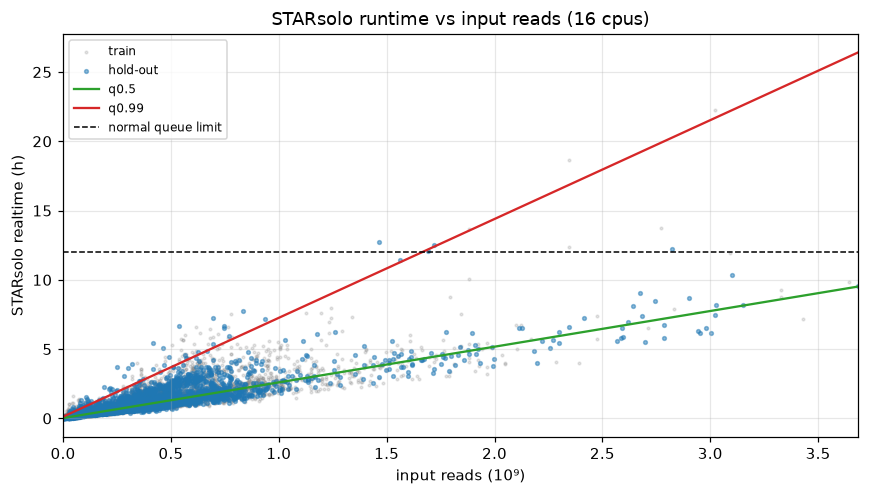

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(train.R, train.hours, s=3, alpha=.2, c='grey', label='train')
ax.scatter(hold.R, hold.hours, s=6, alpha=.5, c='tab:blue', label='hold-out')
for q, c in zip([.5, .99], ['tab:green', 'tab:red']):
    ax.plot(xs.R, tfits[q].predict(xs), c=c, label=f'q{q}')
ax.axhline(NORMAL_LIMIT_H, ls='--', c='k', lw=1, label='normal queue limit')
ax.set(xlabel='input reads (10⁹)', ylabel='STARsolo realtime (h)', xlim=(0, xs.R.max()),
       title='STARsolo runtime vs input reads (16 cpus)')
ax.legend(fontsize=8)
plt.tight_layout()

print(f'successful STARsolo runs over 12 h: {(obs.hours > 12).sum()} of {len(obs)}; '
      f'over 8 h: {(obs.hours > 8).sum()}; max {obs.hours.max():.1f} h')
print(f'runlimit kills (exit 140) in all history, any process: {(df.exit == "140").sum()}')

In [17]:
# Queue wait (submit -> start), where the export has a start time (runlogs; not the live trace).
# Different processes request different shapes, so this compares queues only loosely.
qw = df.assign(wait_h=(pd.to_datetime(df.start, errors='coerce')
                       - pd.to_datetime(df.submit, errors='coerce')).dt.total_seconds() / 3600)
qw = qw[qw.wait_h.notna() & (qw.wait_h >= 0)]
qw.groupby(['queue', 'step']).agg(attempts=('wait_h', 'size'), cpus=('cpus', 'median'), req_gb=('req_gb', 'median'),
                                  wait_median_h=('wait_h', 'median'), wait_p90_h=('wait_h', lambda s: s.quantile(.9)),
                                  wait_max_h=('wait_h', 'max')).round(2)

attempts  cpus  req_gb  wait_median_h  wait_p90_h  wait_max_h
queue    step                                                                          
long     SRA2FASTQ           28658  16.0   128.0           0.00        0.13       29.03
         STARSOLO            22503  16.0   128.0           0.00        0.19       32.25
normal   BAM2FASTQ               5  16.0     4.0           0.00        0.00        0.00
         MAPPINGQC            2196   1.0     2.0           0.00        0.00        0.06
         RENAME10XRUN        58920   1.0     4.0           0.00        0.00        0.06
         RENAME10XSAMPLE     22063   1.0     4.0           0.00        0.00        0.05
transfer FETCH10XMETA         2362   1.0     4.0           0.01        0.19        1.95
         WGET10X             88316   1.0     4.0           0.00        0.08       23.53

## 8. Can the memory closure estimate reads from the FASTQs? (batch 24)

At task time the closure sees only the staged FASTQs. The proposed estimator, implemented in Groovy
in `lib/` and reimplemented here byte for byte, works on each R2 file. STAR's input reads and
read length are the cDNA read's.

1. Stream it through gunzip and count compressed bytes consumed until *N* records have been read.
   This gives compressed bytes per read and mean read length.
2. Estimate reads as file size ÷ bytes-per-read. A file shorter than *N* records is counted exactly.

The sample's estimate is the sum over its R2 files. The staged files are found from each STARsolo
work dir's `.command.run` `ln -s` lines, so killed tasks get an estimate too.

In [18]:
CHECKPOINTS = (10_000, 50_000, 200_000)
CHUNK = 8192            # compressed bytes per read(); bounds the byte-count error at a checkpoint

def sample_gz(path, checkpoints=CHECKPOINTS):
    # -> {N: (compressed_bytes_consumed, mean_len, exact_count_or_None)}
    size = os.path.getsize(path)
    d = zlib.decompressobj(31)
    fed = lines = recs = seqlen = 0
    buf, out, top = b'', {}, max(checkpoints)
    with open(path, 'rb') as fh:
        while recs < top:
            chunk = fh.read(CHUNK)
            if not chunk:
                break
            fed += len(chunk)
            data = d.decompress(chunk)
            while d.unused_data:                      # concatenated gzip members
                rest = d.unused_data
                d = zlib.decompressobj(31)
                data += d.decompress(rest)
            buf += data
            *done, buf = buf.split(b'\n')
            for line in done:
                if lines % 4 == 1:
                    seqlen += len(line)
                lines += 1
                if lines % 4 == 0:
                    recs += 1
                    if recs in checkpoints:
                        out[recs] = (fed, seqlen / recs, None)
                    if recs >= top:
                        break
    for n in checkpoints:                             # file ran out first: the count is exact
        if n not in out:
            out[n] = (size, seqlen / max(recs, 1), recs)
    return size, out

LN = re.compile(r'ln -s (\S+) fastqs/(\S+)')
def staged_r2(workdir):
    p = Path(workdir) / '.command.run'
    if not p.exists():
        return []
    return [src for src, name in LN.findall(p.read_text()) if '_R2_' in name and os.path.exists(src)]

live_star = star[(star.batch == LIVE_BATCH)].sort_values('attempt').drop_duplicates('tag')
jobs = {t: staged_r2(w) for t, w in zip(live_star.tag, live_star.workdir)}
jobs = {t: fs for t, fs in jobs.items() if fs}
files = sorted({f for fs in jobs.values() for f in fs})
print(f'{len(jobs)} batch-24 STARsolo samples with staged R2 files still on disk, {len(files)} files')

# Sampling is the only slow cell; cache it (a .json, so .gitignore keeps it out of git).
# Batch 24's work dirs are the only source, so the cache outlives them on purpose.
SAMPLE_CACHE = REPO / 'notebooks/.cache/fastq_head_samples.json'
cached = json.loads(SAMPLE_CACHE.read_text()) if SAMPLE_CACHE.exists() else {}
sampled = {f: (v[0], {int(n): tuple(t) for n, t in v[1].items()}) for f, v in cached.items()}
todo = [f for f in files if f not in sampled]
with ThreadPoolExecutor(8) as ex:
    sampled.update(zip(todo, ex.map(sample_gz, todo)))
SAMPLE_CACHE.parent.mkdir(parents=True, exist_ok=True)
SAMPLE_CACHE.write_text(json.dumps(sampled))
# the cache also covers files whose work dirs are gone by now
jobs = {t: [f for f in fs if f in sampled] for t, fs in jobs.items()}
print(f'sampled {len(todo)} new files, {len(sampled) - len(todo)} from cache')

423 batch-24 STARsolo samples with staged R2 files still on disk, 1993 files
sampled 0 new files, 1993 from cache


In [19]:
est_rows = []
for tag, fs in jobs.items():
    row = {'tag': tag, 'n_files': len(fs), 'gz_GB': sum(sampled[f][0] for f in fs) / 1e9}
    for n in CHECKPOINTS:
        r_tot = len_w = 0
        for f in fs:
            size, out = sampled[f]
            fed, mlen, exact = out[n]
            r = exact if exact is not None else size / (fed / n)
            r_tot += r
            len_w += r * mlen
        row[f'R_est_{n // 1000}k'] = r_tot / 1e9
        row[f'len_est_{n // 1000}k'] = len_w / r_tot if r_tot else np.nan
    est_rows.append(row)
est = pd.DataFrame(est_rows).merge(lf.rename(columns={'Sample': 'tag'}), on='tag', how='left')
est['R_true'] = est.Rd_all / 1e9
val = est.dropna(subset=['R_true'])

summary = {}
for n in CHECKPOINTS:
    k = n // 1000
    rel = val[f'R_est_{k}k'] / val.R_true - 1
    summary[f'N={k}k'] = {'median rel. err %': 100 * rel.median(), 'p05 %': 100 * rel.quantile(.05),
                          'p95 %': 100 * rel.quantile(.95), 'max |err| %': 100 * rel.abs().max(),
                          'read len exact %': 100 * (val[f'len_est_{k}k'].round() == val.read_len).mean(),
                          'MB read / sample': np.nan}
    summary[f'N={k}k']['MB read / sample'] = np.median([sum(sampled[f][1][n][0] for f in jobs[t]) / 1e6 for t in val.tag])
print(f'validated on {len(val)} samples with Log.final.out')
pd.DataFrame(summary).T.round(1)

validated on 392 samples with Log.final.out


,median rel. err %,p05 %,p95 %,max |err| %,read len exact %,MB read / sample
N=10k,-0.9,-9.5,1.5,52.0,0.0,0.8
N=50k,-0.0,-4.9,2.0,55.3,0.0,4.1
N=200k,0.3,-3.4,2.3,24.3,0.0,16.1


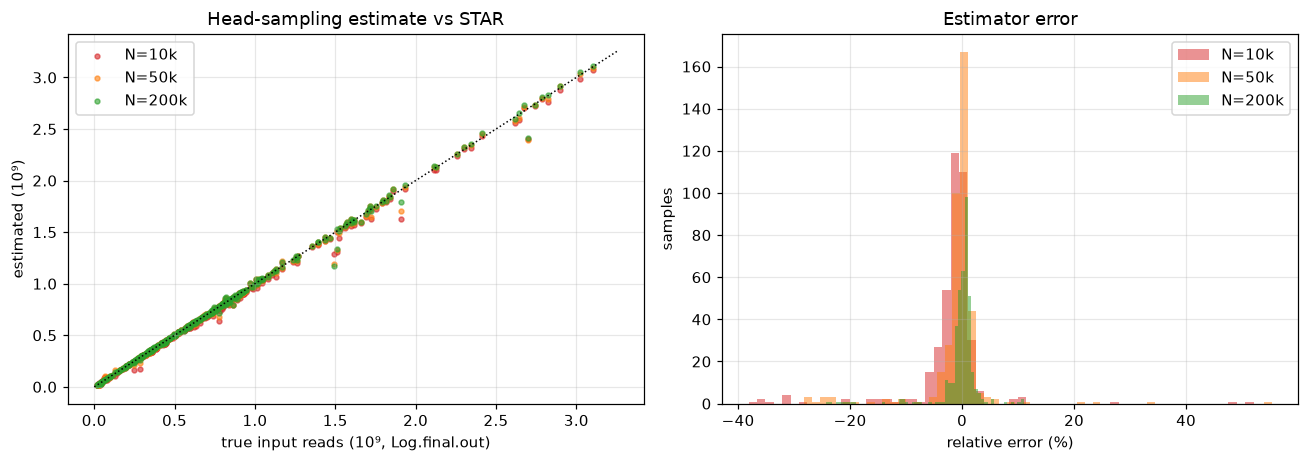

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for n, c in zip(CHECKPOINTS, ['tab:red', 'tab:orange', 'tab:green']):
    k = n // 1000
    ax[0].scatter(val.R_true, val[f'R_est_{k}k'], s=10, alpha=.6, c=c, label=f'N={k}k')
    ax[1].hist(100 * (val[f'R_est_{k}k'] / val.R_true - 1), bins=60, alpha=.5, color=c, label=f'N={k}k')
lim = val.R_true.max() * 1.05
ax[0].plot([0, lim], [0, lim], 'k:', lw=1)
ax[0].set(xlabel='true input reads (10⁹, Log.final.out)', ylabel='estimated (10⁹)', title='Head-sampling estimate vs STAR')
ax[1].set(xlabel='relative error (%)', ylabel='samples', title='Estimator error')
ax[0].legend(); ax[1].legend()
plt.tight_layout()

In [21]:
# Samples with the worst estimates: what are they?
k = 50
val.assign(err=100 * (val[f'R_est_{k}k'] / val.R_true - 1)) \
   .reindex(columns=['tag', 'n_files', 'gz_GB', 'R_true', f'R_est_{k}k', 'err', 'read_len', f'len_est_{k}k']) \
   .sort_values('err', key=abs).tail(10).round(3)

,tag,n_files,gz_GB,R_true,R_est_50k,err,read_len,len_est_50k
373,ERS26972077,1,0.534,0.030,0.023,-24.084,89.0,90.0
325,ERS26971846,1,4.190,0.130,0.161,24.138,263.0,151.0
395,ERS26972075,1,0.530,0.033,0.025,-24.152,89.0,90.0
369,ERS26972076,1,0.570,0.030,0.022,-25.111,89.0,90.0
371,ERS26972079,1,0.638,0.038,0.028,-26.483,89.0,90.0
375,ERS26972078,1,0.611,0.035,0.026,-27.063,89.0,90.0
292,ERS26971850,1,1.154,0.040,0.029,-27.070,263.0,151.0
330,ERS26971853,1,1.006,0.037,0.026,-28.148,263.0,151.0
207,ERS14301423,1,1.382,0.060,0.080,33.251,89.0,90.0
176,ERS14301426,1,1.529,0.065,0.100,55.306,89.0,90.0


## 9. Policy simulation

Every STARsolo sample with known reads and an observed peak is replayed under each policy. The
retry rule is the real one: attempt 1 always retries, and attempt 2 retries only on 130, so there
are at most 3 attempts.

- An attempt succeeds if `request ≥ peak`. Otherwise it is killed after a fraction `f` of the
  successful runtime, with `f` measured from recovered samples.
- **current**: 128 / 256 / 384 GB.
- **model**: `request₁ = roundUp16(max(floor, qfit(R̂)·margin))`, then ×1.5 per attempt, capped at
  `CAP_GB`. R̂ is the true read count perturbed by a resampled estimator error from §8 (*N*=50k).

The model is fitted on batches 9-21, so the hold-out rows (batches 22-24) are the honest test.
Batch 22 is the one that lost 35 samples to memlimit.

In [22]:
CAP_GB = 512              # 'long' queue: standard hosts are mostly 754 GB
RETRY_STEP = 1.5
MAX_ATTEMPTS = 3

# Kill time as a fraction of the successful runtime, from samples that were killed then recovered
rec = star[(star.outcome == 'recovered')]
k_t = rec[rec.censored].groupby(['batch', 'name']).hours.first()
s_t = rec[rec.status == 'COMPLETED'].groupby(['batch', 'name']).hours.first()
kill_frac = float(np.nan_to_num((k_t / s_t).dropna().clip(0, 1).median(), nan=.5))
print(f'a memlimit kill happens after a median {100 * kill_frac:.0f}% of the eventual successful runtime')

def round16(x):
    return np.ceil(np.asarray(x, float) / 16) * 16

def simulate(sample, requests):
    # requests: (n, MAX_ATTEMPTS) array of GB -> per-sample kills, failed, core_h, reserved GB·h
    peak, T, cpu = sample.peak_gb.to_numpy(), sample.hours.to_numpy(), sample.cpus.to_numpy()
    kills = np.zeros(len(sample), int); done = np.zeros(len(sample), bool)
    core_h = np.zeros(len(sample)); res = np.zeros(len(sample))
    for a in range(MAX_ATTEMPTS):
        req = requests[:, a]
        live = ~done
        fits = live & (req >= peak)
        dies = live & ~fits
        core_h += np.where(fits, T * cpu, 0) + np.where(dies, kill_frac * T * cpu, 0)
        res += np.where(fits, req * T, 0) + np.where(dies, req * kill_frac * T, 0)
        kills += dies
        done |= fits
    return pd.Series({'samples': len(sample), 'memlimit kills': kills.sum(), 'never fit': (~done).sum(),
                      'wasted core-h': core_h.sum() - (sample.hours * sample.cpus)[done].sum(),
                      'reserved TB·h': res.sum() / 1e3})

# one row per sample: the successful attempt's peak and runtime
samples = obs.sort_values('attempt').drop_duplicates(['batch', 'tag', 'Rd_all'], keep='last')
rng = np.random.default_rng(0)
err50 = (val['R_est_50k'] / val.R_true).to_numpy()
R_hat = samples.R.to_numpy() * rng.choice(err50, len(samples)) if len(err50) else samples.R.to_numpy()

current = np.tile([128, 256, 384], (len(samples), 1)).astype(float)
results = {('current ladder', '', '', ''): {s: simulate(samples[samples.split == s], current[(samples.split == s).to_numpy()])
                                           for s in ('train', 'holdout')}}
for q in (.95, .99, .995):
    f = qfits[(q, 'peak_gb ~ R')]
    base = f.params.Intercept + f.params.R * R_hat
    for margin in (1.0, 1.1, 1.2):
        for floor in (48, 64):
            r1 = round16(np.maximum(floor, base * margin))
            req = np.minimum(CAP_GB, np.stack([round16(r1 * RETRY_STEP ** a) for a in range(MAX_ATTEMPTS)], 1))
            results[('model', q, margin, floor)] = {s: simulate(samples[samples.split == s], req[(samples.split == s).to_numpy()])
                                                    for s in ('train', 'holdout')}
sim = pd.concat({k: pd.concat(v) for k, v in results.items()}).unstack([-2, -1])
sim.index.names = ['policy', 'q', 'margin', 'floor GB']
sim.round(1)

a memlimit kill happens after a median 78% of the eventual successful runtime


train                                                      holdout                                                     
                                     samples memlimit kills never fit wasted core-h reserved TB·h samples memlimit kills never fit wasted core-h reserved TB·h
policy         q     margin floor GB                                                                                                                          
current ladder                        9873.0           87.0       0.0        5606.7        1279.4  3781.0           86.0       0.0        5905.7         644.8
model          0.95  1.0    48        9873.0           96.0       0.0        1728.6         938.3  3781.0           23.0       0.0         509.7         483.7
                            64        9873.0           87.0       0.0        1684.9         942.8  3781.0           19.0       0.0         492.4         485.9
                     1.1    48        9873.0            8.0       0.0         207.7        1007.4  3781.0            1.0       0.0          16.1         518.2
                            64        9873.0            8.0       0.0         207.7        1009.5  3781.0            1.0       0.0          16.1         519.2
                     1.2    48        9873.0            0.0       0.0           0.0        1089.6  3781.0            0.0       0.0           0.0         564.0
                            64        9873.0            0.0       0.0           0.0        1090.2  3781.0            0.0       0.0           0.0         564.2
               0.99  1.0    48        9873.0           25.0       0.0         475.2         980.4  3781.0            6.0       0.0          90.0         507.3
                            64        9873.0           23.0       0.0         465.1         984.7  3781.0            5.0       0.0          85.8         509.2
                     1.1    48        9873.0            1.0       0.0          15.1        1066.5  3781.0            0.0       0.0           0.0         554.9
                            64        9873.0            1.0       0.0          15.1        1068.4  3781.0            0.0       0.0           0.0         555.7
                     1.2    48        9873.0            0.0       0.0           0.0        1154.3  3781.0            0.0       0.0           0.0         602.4
                            64        9873.0            0.0       0.0           0.0        1154.8  3781.0            0.0       0.0           0.0         602.5
               0.995 1.0    48        9873.0           17.0       0.0         246.3         995.4  3781.0            3.0       0.0          57.0         517.6
                            64        9873.0           15.0       0.0         236.2         999.6  3781.0            3.0       0.0          57.0         519.5
                     1.1    48        9873.0            1.0       0.0          15.1        1086.7  3781.0            0.0       0.0           0.0         566.9
                            64        9873.0            1.0       0.0          15.1        1088.6  3781.0            0.0       0.0           0.0         567.7
                     1.2    48        9873.0            0.0       0.0           0.0        1177.2  3781.0            0.0       0.0           0.0         614.3
                            64        9873.0            0.0       0.0           0.0        1177.8  3781.0            0.0       0.0           0.0         614.5

In [23]:
# Was the simulator calibrated? Kills it predicts for the current ladder vs what really happened
real = star[star.censored & star.R.notna()].groupby('split').size()
print('memlimit kills, current ladder: simulated', dict(sim.loc['current ladder'].xs('memlimit kills', axis=1, level=1).iloc[0]),
      '| observed (with known reads)', dict(real))

memlimit kills, current ladder: simulated {'train': np.float64(87.0), 'holdout': np.float64(86.0)} | observed (with known reads) {'holdout': np.int64(61), 'train': np.int64(39)}


### Time limit and queue

`time₁ = roundUpHour(max(1 h, qfit_t(R̂)·margin))`, doubled on each retry. The task goes to `normal`
if `time ≤ 12 h` and to `long` otherwise. An attempt whose runtime exceeds its limit is killed at
the limit (exit 140) and the whole limit is wasted. **current** is no `time` at all, on `long`.

In [24]:
def simulate_time(sample, limits):
    T, cpu = sample.hours.to_numpy(), sample.cpus.to_numpy()
    done = np.zeros(len(sample), bool); kills = np.zeros(len(sample), int); wasted = np.zeros(len(sample))
    for a in range(MAX_ATTEMPTS):
        lim = limits[:, a]
        fits = ~done & (T <= lim)
        dies = ~done & ~fits
        wasted += np.where(dies, lim * cpu, 0)
        kills += dies
        done |= fits
    return pd.Series({'samples': len(sample), 'to normal %': 100 * (limits[:, 0] <= NORMAL_LIMIT_H).mean(),
                      'runlimit kills': kills.sum(), 'never fit': (~done).sum(), 'wasted core-h': wasted.sum(),
                      'median limit h': np.median(limits[:, 0])})

trows = {}
for q in (.95, .99):
    pred = tfits[q].params.Intercept + tfits[q].params.R * R_hat
    for margin in (1.25, 1.5, 2.0):
        t1 = np.ceil(np.maximum(1, pred * margin))
        lim = np.minimum(LONG_LIMIT_H, np.stack([t1 * 2 ** a for a in range(MAX_ATTEMPTS)], 1))
        trows[(q, margin)] = pd.concat({s: simulate_time(samples[samples.split == s], lim[(samples.split == s).to_numpy()])
                                        for s in ('train', 'holdout')})
tsim = pd.DataFrame(trows).T
tsim.index.names = ['q', 'margin']
tsim.round(1)

train                                                                   holdout                                                                  
            samples to normal % runlimit kills never fit wasted core-h median limit h samples to normal % runlimit kills never fit wasted core-h median limit h
q    margin                                                                                                                                                    
0.95 1.25    9873.0        99.7           72.0       0.0        4400.0            2.0  3781.0        98.9           51.0       0.0        2688.0            2.0
     1.50    9873.0        99.4           29.0       0.0        1664.0            3.0  3781.0        98.3           33.0       0.0        1536.0            3.0
     2.00    9873.0        98.7            9.0       0.0         224.0            3.0  3781.0        97.3           11.0       0.0         560.0            3.0
0.99 1.25    9873.0        99.0           12.0       0.0         512.0            3.0  3781.0        97.5           13.0       0.0         656.0            3.0
     1.50    9873.0        98.4            8.0       0.0         128.0            4.0  3781.0        96.9            4.0       0.0         240.0            4.0
     2.00    9873.0        95.9            5.0       0.0          80.0            5.0  3781.0        94.5            0.0       0.0           0.0            5.0

## 10. Coefficients for `lib/StarsoloResources.groovy`

The chosen rows of §9 set the quantile, the margin and the floor. The cell below prints the
constants in the form the Groovy class takes. Mouse has no data (every run so far was human), and its
2020A index is the same size class, so it shares the human coefficients until mouse runs exist.

In [25]:
CHOSEN_Q, CHOSEN_MARGIN, CHOSEN_FLOOR, CHOSEN_N = .99, 1.1, 48, 50_000
CHOSEN_TQ, CHOSEN_TMARGIN = .99, 2.0
f, ft = qfits[(CHOSEN_Q, 'peak_gb ~ R')], tfits[CHOSEN_TQ]
print(f'''// fitted in notebooks/resource_prediction.ipynb on batches 9-21, n={int(f.nobs)}
// memory: q{CHOSEN_Q} quantile regression; time: q{CHOSEN_TQ}
static final double BASE_GB        = {f.params.Intercept:.1f}
static final double GB_PER_GREAD   = {f.params.R:.1f}
static final double MARGIN         = {CHOSEN_MARGIN}
static final int    FLOOR_GB       = {CHOSEN_FLOOR}
static final double RETRY_STEP     = {RETRY_STEP}
static final double BASE_H         = {ft.params.Intercept:.2f}
static final double H_PER_GREAD    = {ft.params.R:.2f}
static final double TIME_MARGIN    = {CHOSEN_TMARGIN}
static final int    SAMPLE_RECORDS = {CHOSEN_N}''')
print(sim.loc[('model', CHOSEN_Q, CHOSEN_MARGIN, CHOSEN_FLOOR)])
print(sim.loc['current ladder'].iloc[0])
print(tsim.loc[(CHOSEN_TQ, CHOSEN_TMARGIN)])

// fitted in notebooks/resource_prediction.ipynb on batches 9-21, n=11998
// memory: q0.99 quantile regression; time: q0.99
static final double BASE_GB        = 37.7
static final double GB_PER_GREAD   = 111.2
static final double MARGIN         = 1.1
static final int    FLOOR_GB       = 48
static final double RETRY_STEP     = 1.5
static final double BASE_H         = 0.13
static final double H_PER_GREAD    = 7.13
static final double TIME_MARGIN    = 2.0
static final int    SAMPLE_RECORDS = 50000
train    samples           9873.000000
         memlimit kills       1.000000
         never fit            0.000000
         wasted core-h       15.106914
         reserved TB·h     1066.516984
holdout  samples           3781.000000
         memlimit kills       0.000000
         never fit            0.000000
         wasted core-h        0.000000
         reserved TB·h      554.932135
Name: (model, 0.99, 1.1, 48), dtype: float64
train    samples           9873.000000
         memlimit kills    

## 11. SRA2FASTQ: can its memory be predicted too?

SRA2FASTQ requested 128 GB on every first attempt (and up to 384 GB on retries) while §3 shows it
using 4% of that. Before sizing it per run the way STARsolo is sized, check what its peak depends on.
What the memory closure could know at task time is the `.sra` file it is handed (its size), and,
from SRA's run info, the run's spots, read length and sequencing platform.

- `.sra` size: the `write_bytes` of the `WGET10X` task that downloaded it (tag `RUN:RUN`), batches 1-23.
- Run info: SRA's `runinfo` for every run SRA2FASTQ ever converted, fetched once and cached in
  `notebooks/.cache/sra_runinfo.tsv` (execution nodes may have no route out).

In [26]:
RUNINFO_CACHE = REPO / 'notebooks/.cache/sra_runinfo.tsv'
RUNINFO_COLS = ['Run', 'spots', 'bases', 'avgLength', 'size_MB', 'LibraryLayout', 'Platform', 'Model']

def fetch_runinfo(runs, chunk=200):
    import io, time, urllib.request
    rows = []
    for i in range(0, len(runs), chunk):
        url = 'https://trace.ncbi.nlm.nih.gov/Traces/sra-db-be/runinfo?acc=' + ','.join(runs[i:i + chunk])
        rows.append(pd.read_csv(io.StringIO(urllib.request.urlopen(url, timeout=120).read().decode()), dtype=str))
        time.sleep(0.4)
    return pd.concat(rows)[RUNINFO_COLS] if rows else pd.DataFrame(columns=RUNINFO_COLS)

sra = df[(df.step == 'SRA2FASTQ') & (df.status == 'COMPLETED') & df.peak_gb.notna()].copy()
runinfo = pd.read_csv(RUNINFO_CACHE, sep='\t', dtype=str) if RUNINFO_CACHE.exists() else pd.DataFrame(columns=RUNINFO_COLS)
missing = sorted(set(sra.tag) - set(runinfo.Run))
if missing:
    runinfo = pd.concat([runinfo, fetch_runinfo(missing)]).drop_duplicates('Run')
    RUNINFO_CACHE.parent.mkdir(parents=True, exist_ok=True)
    runinfo.to_csv(RUNINFO_CACHE, sep='\t', index=False)
for c in ('spots', 'bases', 'avgLength', 'size_MB'):
    runinfo[c] = pd.to_numeric(runinfo[c], errors='coerce')

# .sra size from the download task, which only the fuller runlogs export carries
wget = pd.concat([pd.read_csv(f, sep='\t', dtype=str, usecols=['process', 'tag', 'status', 'write_bytes'])
                  .assign(batch=f.parts[-3])
                  for f in ARCHIVE.glob('batch*/*/runlogs*.tsv.gz')], ignore_index=True)
wget = wget[wget.process.str.contains('WGET10X', na=False) & (wget.status == 'COMPLETED')]
parts = wget.tag.str.split(':', n=1, expand=True)
wget = wget[parts[0] == parts[1]].assign(run=parts[0], sra_gb=wget.write_bytes.map(to_gb))
sra = (sra.merge(wget[['batch', 'run', 'sra_gb']].drop_duplicates(['batch', 'run']),
                 left_on=['batch', 'tag'], right_on=['batch', 'run'], how='left')
          .merge(runinfo, left_on='tag', right_on='Run', how='left'))
print(f'{len(sra):,} completed SRA2FASTQ attempts; .sra size known for {sra.sra_gb.notna().sum():,}, '
      f'run info for {sra.Platform.notna().sum():,}')
print('Spearman correlation with peak RSS:')
print(sra[['peak_gb', 'sra_gb', 'spots', 'bases', 'avgLength']].corr(method='spearman')['peak_gb'].round(2).to_string())
sra.assign(size_bin=pd.cut(sra.sra_gb, [0, 1, 2, 5, 10, 20, 50, 200])) \
   .groupby('size_bin', observed=True).peak_gb.describe(percentiles=[.5, .99])[['count', '50%', '99%', 'max']].round(2)

28,922 completed SRA2FASTQ attempts; .sra size known for 25,720, run info for 28,922
Spearman correlation with peak RSS:
peak_gb      1.00
sra_gb       0.95
spots        0.93
bases        0.94
avgLength    0.26


,count,50%,99%,max
size_bin,,,,
"(0, 1]",5666.0,1.8,2.5,3.4
"(1, 2]",4130.0,2.8,3.5,4.3
"(2, 5]",7656.0,4.6,5.6,6.4
"(5, 10]",5242.0,5.6,5.6,6.5
"(10, 20]",1914.0,5.6,5.6,6.5
"(20, 50]",965.0,5.6,5.6,96.3
"(50, 200]",147.0,5.6,5.6,5.7


            count  50%    99%   max
Platform                           
BGISEQ       47.0  5.5  81.99  96.3
ILLUMINA  28875.0  4.1   5.60   6.5

Every run above 8 GB, and the runs of the same dataset/platform next to it:


,batch,tag,peak_gb,sra_gb,spots,avgLength,Platform,Model,realtime
12194,batch18,SRR25376447,96.3,25.0,263410684,119,BGISEQ,MGISEQ-2000RS,22m 52s
28752,batch24,SRR8816330,65.2,NaN,301814552,134,BGISEQ,BGISEQ-500,25m 59s


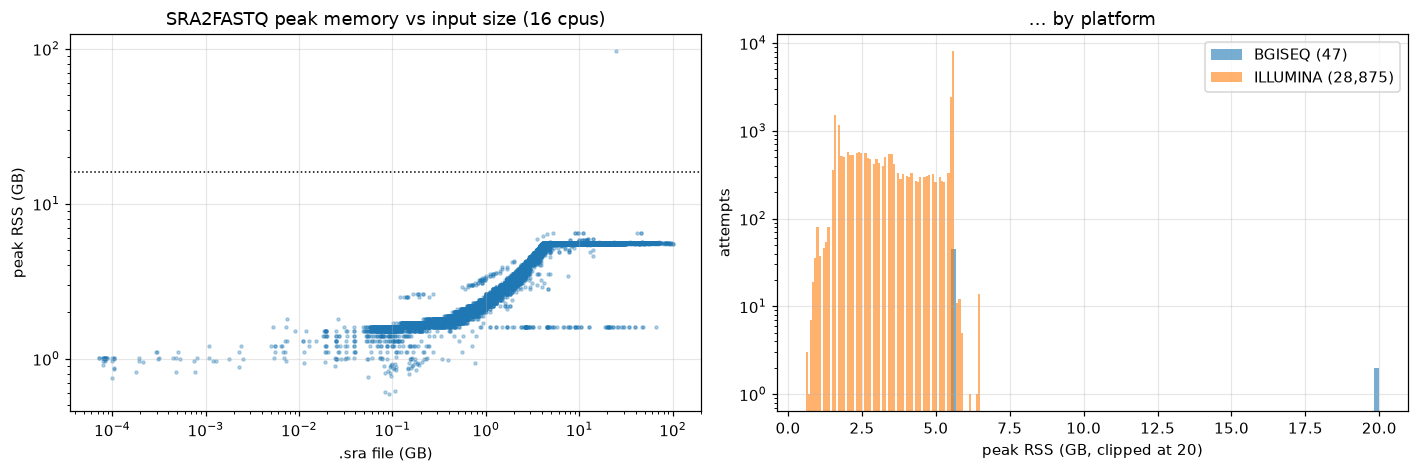

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].scatter(sra.sra_gb, sra.peak_gb, s=4, alpha=.3)
ax[0].set(xscale='log', yscale='log', xlabel='.sra file (GB)', ylabel='peak RSS (GB)',
          title='SRA2FASTQ peak memory vs input size (16 cpus)')
ax[0].axhline(16, ls=':', c='k', lw=1)
for p, d in sra.groupby('Platform'):
    ax[1].hist(d.peak_gb.clip(upper=20), bins=80, alpha=.6, label=f'{p} ({len(d):,})', log=True)
ax[1].set(xlabel='peak RSS (GB, clipped at 20)', ylabel='attempts', title='… by platform')
ax[1].legend()
plt.tight_layout()

print(sra.groupby('Platform').peak_gb.describe(percentiles=[.5, .99])[['count', '50%', '99%', 'max']].round(2))
outliers = sra[sra.peak_gb > 8]
print('\nEvery run above 8 GB, and the runs of the same dataset/platform next to it:')
outliers[['batch', 'tag', 'peak_gb', 'sra_gb', 'spots', 'avgLength', 'Platform', 'Model', 'realtime']]

In [28]:
# Runs on the same sequencer model, in the same batch and anywhere: what did they use?
for _, o in outliers.iterrows():
    same_model = sra[(sra.Model == o.Model) & (sra.tag != o.tag)]
    same_batch = same_model[same_model.batch == o.batch]
    print(f"{o.tag} ({o.Model}, {o.spots:,.0f} spots): {o.peak_gb:.1f} GB | "
          f"{len(same_batch)} other {o.Model} runs in {o.batch}: "
          f"{same_batch.peak_gb.min():.1f}-{same_batch.peak_gb.max():.1f} GB | "
          f"{len(same_model)} in all batches: {same_model.peak_gb.min():.1f}-{same_model.peak_gb.max():.1f} GB")

SRR25376447 (MGISEQ-2000RS, 263,410,684 spots): 96.3 GB | 0 other MGISEQ-2000RS runs in batch18: nan-nan GB | 4 in all batches: 5.5-5.5 GB
SRR8816330 (BGISEQ-500, 301,814,552 spots): 65.2 GB | 41 other BGISEQ-500 runs in batch24: 5.5-5.5 GB | 41 in all batches: 5.5-5.5 GB


### Policy check

Replay every completed attempt (peak known) under each policy, with SRA2FASTQ's own retry rule
(any exit, up to 5 attempts). An attempt is killed when its request is below the run's peak.

In [29]:
def replay(peaks, ladder, max_attempts=5):
    req = np.array([ladder(a) for a in range(1, max_attempts + 1)], float)
    first_fit = np.array([np.argmax(req >= p) if (req >= p).any() else -1 for p in peaks])
    return pd.Series({'kills': int(np.where(first_fit < 0, max_attempts, first_fit).sum()),
                      'never fit': int((first_fit < 0).sum()),
                      'first request GB': req[0],
                      'reserved GB (first attempts, sum)': req[0] * len(peaks)})

peaks = sra.peak_gb.to_numpy()
policies = {
    'old: 128 + 64 per retry': lambda a: 128 + 64 * (a - 1),
    '16 x attempt':            lambda a: 16 * a,
    '16, then 128 (current)':  lambda a: 16 if a == 1 else 128,
    '8, then 128':             lambda a: 8 if a == 1 else 128,
}
pd.DataFrame({k: replay(peaks, f) for k, f in policies.items()}).T

,kills,never fit,first request GB,"reserved GB (first attempts, sum)"
old: 128 + 64 per retry,0.0,0.0,128.0,3702016.0
16 x attempt,9.0,1.0,16.0,462752.0
"16, then 128 (current)",2.0,0.0,16.0,462752.0
"8, then 128",2.0,0.0,8.0,231376.0


### Verdict

SRA2FASTQ's memory is **not worth predicting per run**:

- It is set by the tool, not the input. `parallel-fastq-dump` runs one `fastq-dump` per CPU, and with
  16 CPUs the peak plateaus at ~5.5-6.5 GB from a ~5 GB `.sra` upwards, up to the largest (100 GB)
  files. Below that it is smaller still (1.8 GB median under 1 GB of `.sra`), but at those sizes
  the request hardly matters.
- The only two runs that ever went past 8 GB (SRR25376447, 96 GB; SRR8816330, 65 GB) are not
  explained by anything the closure could know. Both are BGISEQ, but 45 of the 47 BGISEQ runs sat
  at the plateau, including 41 near-identical runs of SRR8816330's own dataset and the batch-19
  runs of SRR25376447's MGISEQ-2000RS model.

So the allocation stays a constant with one safety step: **16 GB on the first attempt, 128 GB on
any retry** (`configs/sra2fastq.config`). The replay shows it loses no run and costs two extra
attempts in ~29,000, where `16 × attempt` would have lost SRR25376447 and killed the outliers nine
times, and the old ladder reserved 8× more memory. `8, then 128` performs the same and halves the
reservation again; 16 keeps 2.5× headroom over the plateau. A size-based model would add a
per-task estimate for no fewer kills.